# Why do Tallinn University students opt in more?

**Question:** Opt-in to the Dish Up launch was 79% for Tallinn University vs 44% for TalTech. Is the school driving this?

**Obvious answer:** Yes. The gap is large and significant (χ² test, p < 0.001).

**The twist:** The survey came in two waves. A late-August push via the Tallinn University student council produced 130 responses, 98% from Tallinn University, with 89% opting in vs 50% in the earlier wave.

**Corrected answer:** Within the early wave, Tallinn University's lead drops from 35 to ~13 points. A logistic regression with school, wave and price shows school is no longer significant (p ≈ 0.13–0.14), while the council wave is (≈7× the odds, p < 0.001). The "school effect" was mostly a recruitment-channel effect.

**What I'd do next:** Track acquisition channel for every user, and compare channels with a proper experiment rather than inferring from survey timing.

**Caveats:** Small groups (EBS n=25), self-selected survey, stated intent rather than real purchases.

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
import statsmodels.formula.api as smf

In [2]:
# Cleaned data from 01_cleaning.ipynb
clean = pd.read_csv("dish_up_surveys_clean.csv")
clean["submitted_at"] = pd.to_datetime(clean["submitted_at"])
print(clean.shape)
clean.head()

FileNotFoundError: [Errno 2] No such file or directory: 'dish_up_surveys_clean.csv'

In [3]:
import os
os.listdir()

['fileOps.zip',
 'CWExampleAppv5',
 'OD_IN_56.csv',
 '24COP504_main_Q1_Q2_Q3nullversion_normalised.ipynb-2.ipynb',
 'model_structure.csv',
 '24COP504_main_Q1_Q2_Q3nullversion_normalised_Final.ipynb-2.ipynb',
 '1ce3a7bf-c983-418d-bd32-06d7ef54d453.MP4',
 'all_in_out_4_5_updated.xml',
 'OD_OUT_67.csv',
 'menu-5.ipynb',
 'B917044 feedback report COP504CW.pdf',
 'CWExampleAppv2',
 'Unknown-5.png',
 'OnMeCard – Business Model & Team.pdf',
 'OD_IN_FIXED_5_6.csv',
 'Fig_robustness_v2.png',
 'Unknown-59.png',
 'Unknown-71.png',
 'Unknown-65.png',
 'CWDatabase-3.db',
 'FitFirst-Furniture-Concept.docx',
 '1 Tableau Induction ( Samet).pptx',
 'IMG_2207.PNG',
 'Model_Types.csv',
 'list2.docx',
 'README-5.md',
 'Business Plan-3.docx',
 'OD_IN_FIXED_1_2.csv',
 'Proposal-Example-1.doc',
 'hourly_counts.csv',
 'other_related_work.csv',
 'IMG_2206.PNG',
 'ChatGPT Image May 1, 2025 at 12_35_39 PM.png',
 'Dish_Up_Cofounder_Equity_Agreement_DRAFT.docx',
 'L4dPerformance.pptx',
 'Authorization_Letter_Key_C

## Step 1: Opt-in rate by school
The mean of a 0/1 column is the opt-in rate. The 95% confidence interval shows how certain each rate is.

In [ ]:
g = clean.groupby("school_group")["launch_opt_in"].agg(["mean", "size"])
g["se"]   = np.sqrt(g["mean"] * (1 - g["mean"]) / g["size"])
g["low"]  = g["mean"] - 1.96 * g["se"]
g["high"] = g["mean"] + 1.96 * g["se"]
g.round(2)

,mean,size,se,low,high
school_group,,,,,
EBS,0.40,25,0.10,0.21,0.59
Other,0.64,22,0.10,0.44,0.84
TalTech,0.44,50,0.07,0.30,0.58
Tallinn University,0.79,183,0.03,0.73,0.85


**Finding:** Tallinn University opts in at 79% (CI 73–85%) vs TalTech 44% (30–58%). The intervals don't overlap.

## Step 2: Is the difference real? Chi-square test

In [ ]:
table = pd.crosstab(clean["school_group"], clean["launch_opt_in"])
chi2, p_value, dof, expected = chi2_contingency(table)
print(f"chi2 = {chi2:.1f}, p-value = {p_value:.2g}")
table

chi2 = 33.2, p-value = 3e-07


launch_opt_in,0,1
school_group,,
EBS,15,10
Other,8,14
TalTech,28,22
Tallinn University,38,145


In [ ]:
# Counts we'd expect if every school had the same opt-in rate
pd.DataFrame(expected, index=table.index, columns=table.columns).round(0)

launch_opt_in,0,1
school_group,,
EBS,8.0,17.0
Other,7.0,15.0
TalTech,16.0,34.0
Tallinn University,58.0,125.0


**Finding:** Opt-in differs across school groups more than chance would explain (p < 0.001). Tallinn University has ~20 more opt-ins than expected. This shows a difference, not its cause.

## Step 3: When did people answer?

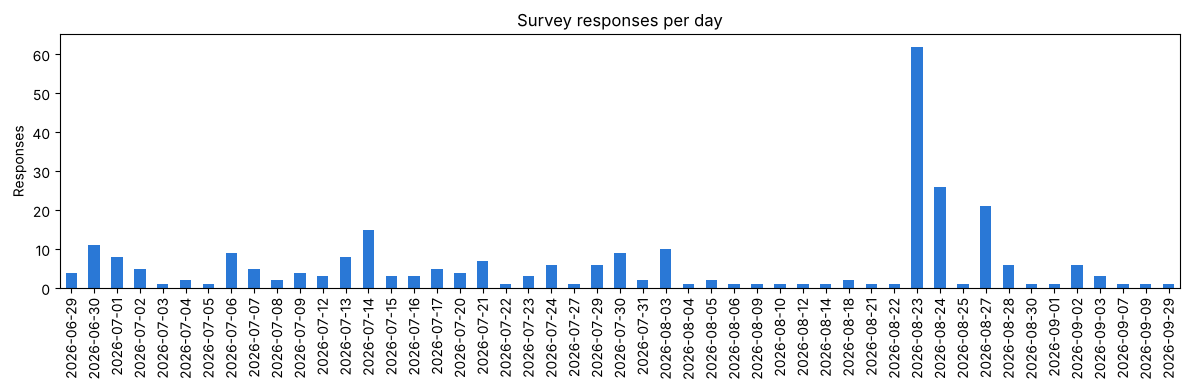

In [ ]:
per_day = clean.groupby(clean["submitted_at"].dt.date).size()

per_day.plot(kind="bar", figsize=(12, 4), color="#2a78d6")
plt.title("Survey responses per day")
plt.ylabel("Responses")
plt.xlabel("")
plt.tight_layout()
plt.show()

In [ ]:
per_day.sort_values(ascending=False).head()

submitted_at
2026-08-23    62
2026-08-24    26
2026-08-27    21
2026-07-14    15
2026-06-30    11
dtype: int64

In [ ]:
# Split at the start of the student-council push (23 Aug)
is_early = clean["submitted_at"] < "2026-08-23"
clean["wave"] = np.where(is_early, "early", "council")
clean["is_tlu"] = clean["school_group"] == "Tallinn University"

waves = clean.groupby("wave").agg(
    opt_in_rate = ("launch_opt_in", "mean"),
    tlu_share   = ("is_tlu", "mean"),
    responses   = ("launch_opt_in", "size"),
)
waves.round(2)

,opt_in_rate,tlu_share,responses
wave,,,
council,0.89,0.98,130
early,0.50,0.37,150


In [ ]:
# Robustness check: does a different cut-off (15 Aug) change the picture?
alt_wave = np.where(clean["submitted_at"] < "2026-08-15", "early", "council")
clean.groupby(alt_wave).agg(
    opt_in_rate = ("launch_opt_in", "mean"),
    tlu_share   = ("is_tlu", "mean"),
    responses   = ("launch_opt_in", "size"),
).round(2)

,opt_in_rate,tlu_share,responses
council,0.90,0.95,134
early,0.49,0.38,146


**Finding:** The council wave (from 23 Aug) was 98% Tallinn University and opted in at 89%, vs 50% in the early wave. Moving the cut-off to 15 Aug changes rates by at most one point. School and recruitment channel are tangled together.

## Step 4: Compare schools within the early wave only

In [ ]:
early = clean[clean["wave"] == "early"].copy()
g_early = early.groupby("school_group")["launch_opt_in"].agg(["mean", "size"])
g_early.round(2)

,mean,size
school_group,,
EBS,0.40,25
Other,0.67,21
TalTech,0.42,48
Tallinn University,0.55,56


In [ ]:
lead_overall = g.loc["Tallinn University", "mean"] - g.loc["TalTech", "mean"]
lead_early   = g_early.loc["Tallinn University", "mean"] - g_early.loc["TalTech", "mean"]
print(f"Tallinn University lead over TalTech, overall:     {lead_overall:.0%}")
print(f"Tallinn University lead over TalTech, early wave:  {lead_early:.0%}")

Tallinn University lead over TalTech, overall:     35%
Tallinn University lead over TalTech, early wave:  14%


**Finding:** The lead shrinks from 35 points overall to ~14 points within the early wave. Most of the gap came from the council email recruiting already-interested Tallinn University students.

## Step 5: Logistic regression
Model 1 uses school only. Model 2 adds wave and price, so each effect is estimated while holding the others fixed. Baselines: Tallinn University, early wave.

In [ ]:
m1 = smf.logit(
    "launch_opt_in ~ C(school_group, Treatment('Tallinn University'))",
    data=clean,
).fit(disp=0)

m2 = smf.logit(
    "launch_opt_in ~ C(school_group, Treatment('Tallinn University'))"
    " + C(wave, Treatment('early')) + price_eur",
    data=clean,
).fit(disp=0)

NameError: name 'clean' is not defined

In [ ]:
m2.params

NameError: name 'm2' is not defined

In [ ]:
# Odds ratios: how many times the odds of opting in change
np.exp(m2.params).rename(index=labels).drop(index="Intercept").round(2)

EBS vs TLU               0.48
Other vs TLU             1.15
TalTech vs TLU           0.56
Council vs early wave    6.81
Price (+1 EUR)           1.22
dtype: float64

**Finding:** In model 1, TalTech and EBS are significantly less likely to opt in (p < 0.001). Once wave is added, those effects more than halve and stop being significant (p ≈ 0.13–0.14). The council wave is the dominant factor: ≈7× the odds of opting in (p < 0.001). Price has a small, borderline effect (p ≈ 0.09).